# 04 - Leave one attack out

How well do the detectors catch an attack category excluded from model fitting and threshold calibration? For each held-out category:

- its rows are removed from the training and the validation part;
- the random forest is retrained without it, using the fixed hyperparameters from `02_supervised`;
- every model gets its threshold at 1% FPR on the validation part without that category;
- detection is measured on the distinct test rows of that category.

The hyperparameter search in `02_supervised` included all attack categories. This experiment measures the effect of holding out a category during random forest retraining and threshold calibration with those hyperparameters fixed.

Isolation Forest and the autoencoder are fitted on normal flows, which are the same in every round. Their configurations are fixed across rounds using the experiments in `03_anomaly`. Isolation Forest uses all normal training flows and all columns, and the autoencoder uses k=4. The validation comparisons in `03_anomaly` included all attack categories.

Held out: Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance. Not used: Fuzzers (the random forest already misses most of it when it has seen it), Shellcode (both anomaly detectors catch none of it), Worms (44 test rows).

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.pipeline import make_pipeline

from netad.data import load_unsw_frame, train_val_split, distinct_rows, FEATURES
from netad.preprocessing import build_preprocessor
from netad.evaluation import FIGURES_DIR, REPORTS_DIR, RESULTS_PATH, choose_threshold
from netad.models.autoencoder import train_autoencoder, reconstruction_error

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")

X_test = test_df[FEATURES]
test_cats = test_df["attack_cat"].to_numpy()
distinct = distinct_rows(test_df).to_numpy()

X_tr, X_val, y_tr, y_val = train_val_split(train_df, "label")
cat_tr = train_df.loc[X_tr.index, "attack_cat"].to_numpy()
cat_val = train_df.loc[X_val.index, "attack_cat"].to_numpy()

MAX_FPR = 0.01
HELD_OUT = ["Analysis", "Backdoor", "DoS", "Exploits", "Generic", "Reconnaissance"]
torch.manual_seed(42)

saved = {(r["model"], r["task"]): r for r in json.loads(RESULTS_PATH.read_text(encoding="utf-8"))}
rf_params = {k: v for k, v in saved[("RandomForest", "binary")]["params"].items() if k in RandomForestClassifier().get_params()}
rf_params

{'n_estimators': 800,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'max_depth': 20}

## Anomaly detectors

Trained once on the normal flows of the training part, which are the same whatever category is held out.

In [4]:
X_normal = X_tr[(y_tr == 0).to_numpy()]
X_val_normal = X_val[(y_val == 0).to_numpy()]

iforest = make_pipeline(
    build_preprocessor(),
    IsolationForest(n_estimators=300, max_samples=1.0, random_state=42, n_jobs=-1),
).fit(X_normal)

pre = build_preprocessor().fit(X_normal)
def to_ae(X):
    return np.asarray(pre.transform(X), dtype=np.float32)

ae, history = train_autoencoder(to_ae(X_normal), to_ae(X_val_normal), bottleneck=4, seed=42)

anomaly_val = {"IsolationForest": -iforest.score_samples(X_val), "Autoencoder": reconstruction_error(ae, to_ae(X_val))}
anomaly_test = {"IsolationForest": -iforest.score_samples(X_test), "Autoencoder": reconstruction_error(ae, to_ae(X_test))}
len(history)

358

## Loop over held-out categories

For the random forest the held-out rows of test fall in two groups: rows whose feature vector is in the training part as another attack ("look-alikes", e.g. Analysis flows identical to Exploits flows), and the rest. Flagging a look-alike is recognising a known attack under another name, not detecting a new one.

In [5]:
normal_test = test_cats == "Normal"
rows = {}
for cat in HELD_OUT:
    keep_tr, keep_val = cat_tr != cat, cat_val != cat
    rf = make_pipeline(
        build_preprocessor(), RandomForestClassifier(random_state=42, n_jobs=-1, **rf_params),
    ).fit(X_tr[keep_tr], y_tr[keep_tr])

    scores_val = {"RandomForest": rf.predict_proba(X_val[keep_val])[:, 1],
                  **{name: s[keep_val] for name, s in anomaly_val.items()}}
    scores_test = {"RandomForest": rf.predict_proba(X_test)[:, 1], **anomaly_test}

    target = distinct & (test_cats == cat)
    known_attacks = X_tr[keep_tr & (y_tr == 1).to_numpy()].drop_duplicates()
    lookalike = (test_df[FEATURES].merge(known_attacks.assign(_known=True), on=FEATURES, how="left")["_known"]
                 .notna().to_numpy())

    row = {
        "test rows": int(target.sum()),
        "RandomForest, seen": saved[("RandomForest", "binary")]["test_distinct"]["by_category"][cat]["flagged"],
    }
    for name in scores_val:
        threshold = choose_threshold(y_val[keep_val], scores_val[name], "fpr", max_fpr=MAX_FPR)
        flagged = scores_test[name] >= threshold
        row[name] = flagged[target].mean()
        row[f"{name} FPR"] = flagged[normal_test].mean()
        if name == "RandomForest":
            row["look-alike share"] = lookalike[target].mean()
            row["RandomForest on look-alikes"] = flagged[target & lookalike].mean() if (target & lookalike).any() else np.nan
            row["RandomForest on the rest"] = flagged[target & ~lookalike].mean() if (target & ~lookalike).any() else np.nan
    rows[cat] = row

loo = pd.DataFrame(rows).T
loo.to_csv(REPORTS_DIR / "leave_one_out.csv")
loo[["test rows", "RandomForest, seen", "RandomForest", "IsolationForest", "Autoencoder"]].round(3)

,test rows,"RandomForest, seen",RandomForest,IsolationForest,Autoencoder
Analysis,446.0,0.870,0.868,0.825,0.776
Backdoor,346.0,0.980,0.968,0.847,0.827
DoS,1718.0,0.919,0.889,0.391,0.377
Exploits,7609.0,0.928,0.758,0.174,0.208
Generic,3657.0,0.976,0.287,0.800,0.801
Reconnaissance,2703.0,0.954,0.483,0.096,0.092


For each held-out category, compare the random forest detection rates on exact training matches and on the remaining distinct attack flows. The FPR columns use all normal test flows. The random forest baseline with all categories included has 3.97% test FPR in `02`.

In [6]:
loo[["look-alike share", "RandomForest on look-alikes", "RandomForest on the rest",
     "RandomForest FPR", "IsolationForest FPR", "Autoencoder FPR"]].round(3)

,look-alike share,RandomForest on look-alikes,RandomForest on the rest,RandomForest FPR,IsolationForest FPR,Autoencoder FPR
Analysis,0.206,1.000,0.833,0.040,0.026,0.032
Backdoor,0.000,NaN,0.968,0.042,0.026,0.032
DoS,0.113,1.000,0.875,0.041,0.026,0.032
Exploits,0.023,1.000,0.753,0.043,0.026,0.032
Generic,0.005,1.000,0.283,0.043,0.026,0.032
Reconnaissance,0.063,0.994,0.449,0.040,0.026,0.032


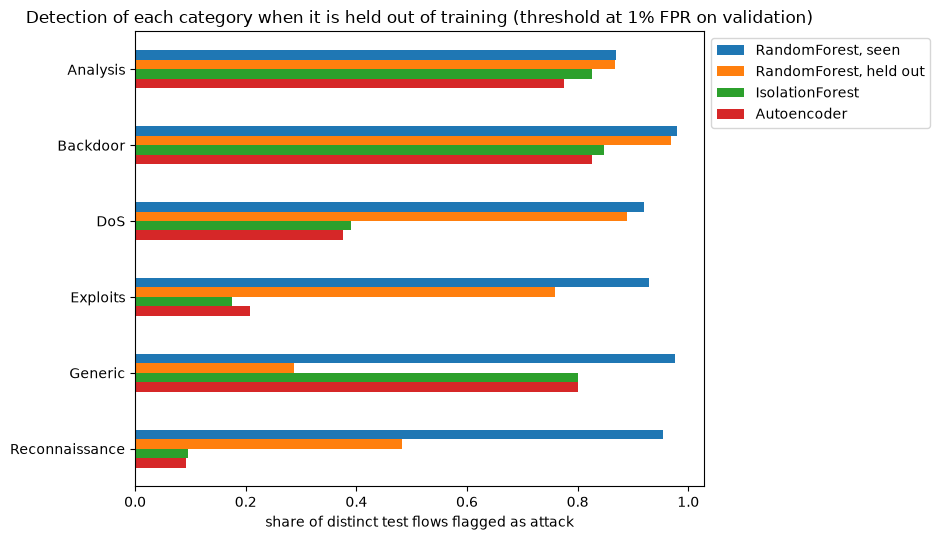

In [7]:
ax = loo[["RandomForest, seen", "RandomForest", "IsolationForest", "Autoencoder"]].rename(
    columns={"RandomForest": "RandomForest, held out"}
).plot.barh(figsize=(9.5, 5.5))
ax.invert_yaxis()
ax.set_xlabel("share of distinct test flows flagged as attack")
ax.set_title("Detection of each category when it is held out of training (threshold at 1% FPR on validation)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "leave_one_out.png", dpi=120)
plt.show()

## Conclusions

1. **Generic is the case for anomaly detection.** Held out of training, the random forest catches 29% of the distinct Generic test flows (98% when it has seen them). Isolation Forest and the autoencoder catch 80%, without having been shown any attack. For this category, both anomaly detectors reach higher recall at lower test FPR (2.64% and 3.15%, compared with 4.31% for the held-out random forest).
2. **For most categories the supervised model still wins without having seen them.** Held out, the random forest catches 97% of Backdoor, 89% of DoS, 87% of Analysis and 76% of Exploits, against 17-85% for the anomaly detectors. Exact look-alikes (the same feature vector in training as another attack) are a small part of it: 21% of Analysis, 11% of DoS, none of Backdoor. Among flows without an exact match to a retained training attack, the forest detects 97% of Backdoor, 87% of DoS, 83% of Analysis and 75% of Exploits. Exact matches explain only part of the detection.
3. **All three models miss most Reconnaissance flows when the category is held out.** The random forest drops from 95% to 48%, the anomaly detectors stay under 10%. Exploits: 93% -> 76% for the forest, about 20% for the anomaly detectors.
4. **The detectors cover different parts of this benchmark.** The anomaly detectors have higher recall for held-out Generic, while the random forest leads on the other five categories. Across all distinct attack flows in `03`, the anomaly detectors miss about 70%, with 2.6-3.2% FPR across all normal test flows.
5. **Limits.** Six categories held out, one random forest each with one seed; Fuzzers, Shellcode and Worms are left out for the reasons above. The hyperparameters and anomaly detector settings were picked with every category present, only the training and threshold exclude the held-out one. The thresholds selected under a 1% validation FPR budget give 4.0-4.3% on test for the forest and 2.6% / 3.2% for the anomaly detectors, the same shift as in `02` and `03`.